# Freight rate prediction

Predict `posted_rate` for the 12,000 loads in `validation.csv`, and fill the fixed December chart.

Outline
1. Load and check the data
2. Key findings that drive the model
3. Features and the daily market table
4. Model
5. Forward-in-time validation
6. Final fit, predictions, December chart, scorer

In [1]:
import os, sys, zipfile, subprocess, warnings
import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold
from IPython.display import Image, display

warnings.filterwarnings("ignore")

ZIP_PATH = "spotter.zip"      # only used if the files are zipped
OUT_DIR = "outputs"           # outputs from the notebook goes here
RUN_EVAL = True               # False skips the validation tables

T0 = pd.Timestamp("2025-01-01")
SEEDS = (1, 2, 3)
STATIC = ["pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon", "distance", "logd", "weight", "eq"]
ROW = STATIC + ["market_index", "quote_signal", "mi_dev", "qs_dev", "dow"]
GBM = dict(objective="huber", alpha=0.15, learning_rate=0.05, num_leaves=31, min_child_samples=40,
           subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1, n_jobs=4)

os.makedirs(OUT_DIR, exist_ok=True)

## 1. Load and check the data

In [3]:
REQUIRED = ["train-test.csv", "validation.csv", "validation-predictions-template.csv", "december-chart-inputs.csv", "score.py"]

def resolve(folder, name):
    for n in (name, name.replace("-", "_")):
        p = os.path.join(folder, n)
        if os.path.exists(p):
            return p
    return None

def find_data_dir(zip_path, out_dir):
    for folder in (".", "spotter", "data"):
        if all(resolve(folder, f) for f in REQUIRED):
            return folder
    if os.path.exists(zip_path):
        extract = os.path.join(out_dir, "extracted_spotter")
        if not os.path.exists(extract):
            with zipfile.ZipFile(zip_path) as z:
                z.extractall(extract)
        for root, _, _ in os.walk(extract):
            if all(resolve(root, f) for f in REQUIRED):
                return root
    raise FileNotFoundError("Could not find the assessment files. Put them next to this notebook, "
                            "in a folder named spotter, or set ZIP_PATH to a zip that contains them.")

data_dir = find_data_dir(ZIP_PATH, OUT_DIR)
print("reading data from:", os.path.abspath(data_dir))

train_raw = pd.read_csv(resolve(data_dir, "train-test.csv"), parse_dates=["date"])
valid_raw = pd.read_csv(resolve(data_dir, "validation.csv"), parse_dates=["date"])
template = pd.read_csv(resolve(data_dir, "validation-predictions-template.csv"))
dec_raw = pd.read_csv(resolve(data_dir, "december-chart-inputs.csv"), parse_dates=["date"])
score_script = resolve(data_dir, "score.py")

print("train", train_raw.shape, train_raw.date.min().date(), "to", train_raw.date.max().date())
print("valid", valid_raw.shape, valid_raw.date.min().date(), "to", valid_raw.date.max().date())

reading data from: c:\Users\Hp\Desktop\Freight rate prediction\spotter
train (48000, 14) 2025-01-01 to 2025-10-31
valid (12000, 13) 2025-11-01 to 2025-12-31


In [4]:
# Data-quality checks
unseen = (set(valid_raw.pickup) | set(valid_raw.delivery)) - (set(train_raw.pickup) | set(train_raw.delivery))
rpm = train_raw.posted_rate / train_raw.distance
print("duplicate load_id (train):", train_raw.load_id.duplicated().sum())
print("missing weight    train / valid:", train_raw.weight.isna().sum(), "/", valid_raw.weight.isna().sum())
print("missing market_index train / valid:", train_raw.market_index.isna().sum(), "/", valid_raw.market_index.isna().sum())
print("negative weight   train / valid:", (train_raw.weight < 0).sum(), "/", (valid_raw.weight < 0).sum())
print("cities only in validation:", sorted(unseen))
print("validation rows touching those cities: %.1f%%" % (100 * (valid_raw.pickup.isin(unseen) | valid_raw.delivery.isin(unseen)).mean()))
print("rows with rate per mile outside [1, 5]: %d (%.2f%%)" % ((~rpm.between(1, 5)).sum(), 100 * (~rpm.between(1, 5)).mean()))

duplicate load_id (train): 0
missing weight    train / valid: 300 / 165
missing market_index train / valid: 374 / 249
negative weight   train / valid: 292 / 145
cities only in validation: ['Allentown', 'Charlotte', 'Chicago', 'Jackson', 'Knoxville', 'Laredo', 'Norfolk', 'San Diego']
validation rows touching those cities: 12.1%
rows with rate per mile outside [1, 5]: 646 (1.35%)


## 2. Key findings

- Validation is Nov and Dec, while the labeled data is Jan to Oct. So validation has to be forward in time. A shuffled K-fold lets the model see other loads from the same day and looks better than it is.
- About 1.5% of labels are random spikes (roughly 2 to 5 times too high, or 0.2 to 0.6 times too low). A model could not predict which loads they hit, so the loss should not chase them.
- Rate per mile mostly falls with distance and differs by equipment. On top of that there is a market level for each day, which follows the daily average of `market_index` and `quote_signal` plus a slow upward trend.
- The lat/lon columns are approximate, not real city coordinates. `distance` is the field to trust.

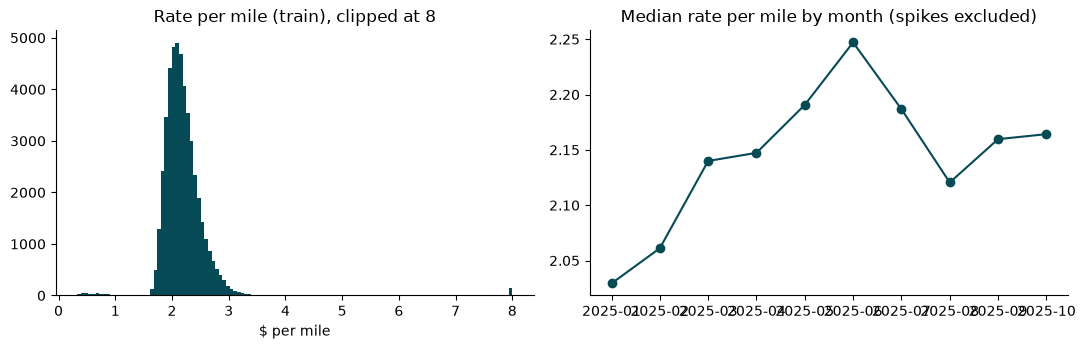

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(rpm.clip(0, 8), bins=120, color="#064A56")
ax[0].set_title("Rate per mile (train), clipped at 8")
ax[0].set_xlabel("$ per mile")
m = rpm[rpm.between(1, 5)].groupby(train_raw.date.dt.to_period("M")).median()
ax[1].plot(m.index.astype(str), m.values, marker="o", color="#064A56")
ax[1].set_title("Median rate per mile by month (spikes excluded)")
for a in ax:
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 3. Features and the daily market table

- Negative weights are flipped to positive (the sign looks like an entry error). This is done on an in-memory copy.
- `market_index` and `quote_signal` are noisy per row, so their mean per day is a much cleaner market signal. The daily table is built from the feature columns of both train and validation. It uses no labels.
- `tday` is the time in months since 2025-01-01. It lets the daily model carry the upward trend into Nov and Dec.

In [6]:
def add_basic_features(df):
    df = df.copy()
    df["weight"] = df["weight"].abs()
    df["eq"] = df["equipment"].map({"Dry Van": 0, "Flatbed": 1, "Reefer": 2})
    df["logd"] = np.log(df["distance"])
    df["dow"] = df["date"].dt.dayofweek
    return df

def build_daily_table(train, valid):
    both = pd.concat([train[["date", "market_index", "quote_signal"]], valid[["date", "market_index", "quote_signal"]]])
    d = both.groupby("date").agg(d_mi=("market_index", "mean"), d_qs=("quote_signal", "mean")).sort_index()
    d["tday"] = (d.index - T0).days / 30.0
    d["mi_l1"] = d["d_mi"].shift(1).bfill()
    d["mi_l2"] = d["d_mi"].shift(2).bfill()
    return d

def attach_daily(df, daily):
    df = df.join(daily[["d_mi", "d_qs", "tday"]], on="date")
    df["mi_dev"] = df["market_index"].fillna(df["d_mi"]) - df["d_mi"]
    df["qs_dev"] = df["quote_signal"] - df["d_qs"]
    return df

daily = build_daily_table(train_raw, valid_raw)
train = attach_daily(add_basic_features(train_raw), daily)
valid = attach_daily(add_basic_features(valid_raw), daily)
daily.head()

,d_mi,d_qs,tday,mi_l1,mi_l2
date,,,,,
2025-01-01,0.961224,2.052912,0.000000,0.961224,0.961224
2025-01-02,0.986606,2.067495,0.033333,0.961224,0.961224
2025-01-03,0.940339,2.051359,0.066667,0.986606,0.961224
2025-01-04,0.857702,2.038972,0.100000,0.940339,0.986606
2025-01-05,0.801855,2.078432,0.133333,0.857702,0.940339


## 4. Model

Target is log(rate per mile). Two stages:

1. A GBM on load features only (distance, equipment, weight, location). Its out-of-fold residual, averaged per day, is the market level of that day.
2. A small linear model explains that daily level from the daily `market_index`, `quote_signal` and the time trend. A linear model can extrapolate to Nov and Dec, a tree model cannot. Two variants are averaged (with and without lagged `market_index`).
3. A second GBM (3 seeds) learns the row-level structure with the actual daily level taken out.

All GBMs use a Huber loss, so the random spikes do not pull the fit.

Prediction = distance x exp(row model + daily level).

In [7]:
def _gbm(seed, n):
    return lgb.LGBMRegressor(**GBM, n_estimators=n, random_state=seed)

def _daily_design(d, kind):
    if kind == "A":
        cols = [d["d_mi"], d["d_qs"], d["tday"]]
    else:
        cols = [d["d_mi"], d["mi_l1"], d["mi_l2"], d["d_qs"], d["tday"]]
    return np.c_[(np.ones(len(d)),) + tuple(c.values for c in cols)]

class FreightModel:
    def fit(self, tr, daily):
        y = np.log(tr["posted_rate"].values / tr["distance"].values)

        # stage 1: load effect only, out-of-fold
        oof = np.zeros(len(tr))
        for a, b in KFold(4, shuffle=True, random_state=0).split(tr):
            m = _gbm(1, 400).fit(tr.iloc[a][STATIC], y[a])
            oof[b] = m.predict(tr.iloc[b][STATIC])
        r0 = y - oof
        sd = 1.4826 * np.median(np.abs(r0 - np.median(r0)))
        keep = np.abs(r0) < 6 * sd                      # drop the random spikes before averaging per day
        level = pd.Series(r0[keep]).groupby(tr["date"].values[keep]).mean()
        level.index = pd.to_datetime(level.index)
        self.level = level

        # daily model
        dd = daily.loc[level.index]
        self.beta = {k: np.linalg.lstsq(_daily_design(dd, k), level.values, rcond=None)[0] for k in "AB"}

        # stage 2: row model with the actual daily level removed
        off = tr["date"].map(level).fillna(0).values
        self.row_models = [_gbm(s, 500).fit(tr[ROW], y - off) for s in SEEDS]
        return self

    def daily_level(self, dates, daily):
        d = daily.loc[dates]
        pred = np.mean([_daily_design(d, k) @ self.beta[k] for k in "AB"], axis=0)
        return pd.Series(pred, index=d.index)

    def predict(self, df, daily):
        lvl = self.daily_level(sorted(df["date"].unique()), daily)
        row = np.mean([m.predict(df[ROW]) for m in self.row_models], axis=0)
        return df["distance"].values * np.exp(row + df["date"].map(lvl).values)

## 5. Forward-in-time validation

Train on earlier months, test on later months. Three tests:
- Jul to Aug, trained on Jan to Jun
- Sep to Oct, trained on Jan to Aug (closest to the real situation)
- Sep to Oct on cities the model never saw in training (1 city in 8 held out)

The baseline is a plain LightGBM on the raw columns with squared error. "Clean" rows are the ones whose rate per mile is inside [1, 5], so the random spikes are left out. RMSE on all rows is dominated by those spikes whatever the model does.

In [8]:
def metrics(y, p):
    e = p - y
    return {"rmse": float(np.sqrt(np.mean(e ** 2))), "mae": float(np.mean(np.abs(e))), "mape": float(np.mean(np.abs(e) / y))}

def baseline_fit_predict(tr, te):
    cols = ["pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon", "distance", "weight", "market_index", "quote_signal", "eq", "dow"]
    m = lgb.LGBMRegressor(objective="regression", learning_rate=0.03, num_leaves=31, min_child_samples=40, subsample=0.8,
                          subsample_freq=1, colsample_bytree=0.8, n_estimators=600, random_state=1, verbose=-1, n_jobs=4)
    return m.fit(tr[cols], tr["posted_rate"]).predict(te[cols])

def evaluate(train, daily):
    rows = []
    mon = train["date"].dt.month
    clean_mask = (train["posted_rate"] / train["distance"]).between(1, 5)
    cities = sorted(set(train["pickup"]) | set(train["delivery"]))
    held = set(cities[::8])
    touches = train["pickup"].isin(held) | train["delivery"].isin(held)
    tests = {
        "Jul-Aug (train Jan-Jun)": (mon < 7, mon.isin([7, 8])),
        "Sep-Oct (train Jan-Aug)": (mon < 9, mon.isin([9, 10])),
        "Sep-Oct, unseen cities": ((mon < 9) & ~touches, mon.isin([9, 10]) & touches),
    }
    for name, (itr, ite) in tests.items():
        tr, te = train[itr], train[ite]
        y = te["posted_rate"].values
        cm = clean_mask[ite].values
        fm = FreightModel().fit(tr, daily)
        for label, p in [("baseline LightGBM", baseline_fit_predict(tr, te)), ("final model", fm.predict(te, daily))]:
            a, c = metrics(y, p), metrics(y[cm], p[cm])
            rows.append({"test": name, "model": label,
                         "rmse_all": a["rmse"], "mae_all": a["mae"], "mape_all": a["mape"],
                         "rmse_clean": c["rmse"], "mae_clean": c["mae"], "mape_clean": c["mape"]})
    return pd.DataFrame(rows)

if RUN_EVAL:
    results = evaluate(train, daily)
    results.to_csv(os.path.join(OUT_DIR, "validation_results.csv"), index=False)
    display(results.round(4))

,test,model,rmse_all,mae_all,mape_all,rmse_clean,mae_clean,mape_clean
0,Jul-Aug (train Jan-Jun),baseline LightGBM,630.5659,136.9641,0.0661,143.4756,86.4787,0.0443
1,Jul-Aug (train Jan-Jun),final model,624.6239,127.2653,0.0566,135.6484,76.5963,0.0342
2,Sep-Oct (train Jan-Aug),baseline LightGBM,644.2070,150.7145,0.0677,198.3912,98.8937,0.0435
3,Sep-Oct (train Jan-Aug),final model,632.4335,99.5465,0.0425,154.4211,46.9000,0.0180
4,"Sep-Oct, unseen cities",baseline LightGBM,557.4354,147.7669,0.0665,200.9104,102.0701,0.0480
5,"Sep-Oct, unseen cities",final model,540.0696,90.8367,0.0373,149.5058,44.4236,0.0182


## 6. Final fit on all labeled data, predictions, December chart, scorer

In [9]:
model = FreightModel().fit(train, daily)

valid_pred = valid[["load_id"]].assign(predicted_rate=model.predict(valid, daily))
sub = template[["load_id"]].merge(valid_pred, on="load_id", how="left")
assert len(sub) == 12000 and sub["predicted_rate"].notna().all()

pred_path = os.path.join(OUT_DIR, "validation_predictions.csv")
sub.to_csv(pred_path, index=False)
print("saved", pred_path)
sub.describe()

saved outputs\validation_predictions.csv


,predicted_rate
count,12000.000000
mean,2398.111661
std,1386.898844
min,187.267721
25%,1289.163150
50%,2075.321095
75%,3408.995324
max,6865.155812


December chart rows: Lexington to Fort Wayne, 360 miles, Dry Van, 32,000 lb, only the date changes.
These rows have no `market_index` or `quote_signal`, so the daily means from `validation.csv` (features only, no labels) are used. Pickup and delivery coordinates are the ones the training data uses for those two cities.

In [10]:
def december_frame(train, dec, daily):
    d = dec.copy()
    pk = train.loc[train["pickup"] == "Lexington", ["pickup_lat", "pickup_lon"]].iloc[0]
    dl = train.loc[train["delivery"] == "Fort Wayne", ["delivery_lat", "delivery_lon"]].iloc[0]
    d["pickup_lat"], d["pickup_lon"] = pk["pickup_lat"], pk["pickup_lon"]
    d["delivery_lat"], d["delivery_lon"] = dl["delivery_lat"], dl["delivery_lon"]
    d["market_index"] = d["date"].map(daily["d_mi"])
    d["quote_signal"] = d["date"].map(daily["d_qs"])
    d = add_basic_features(d)
    return attach_daily(d, daily)

dec_in = december_frame(train, dec_raw, daily)
dec_out = dec_raw.copy()
dec_out["date"] = dec_out["date"].dt.strftime("%Y-%m-%d")
dec_out["predicted_rate"] = model.predict(dec_in, daily)

dec_path = os.path.join(OUT_DIR, "december_chart_inputs.csv")
dec_out.to_csv(dec_path, index=False)
dec_out.head()

,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,829.083466
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,837.516504
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,846.483232
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,850.474610
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,844.654572


Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: outputs\scorer_results\candidate_december.png
Final validation metrics are calculated by Spotter after submission.
 


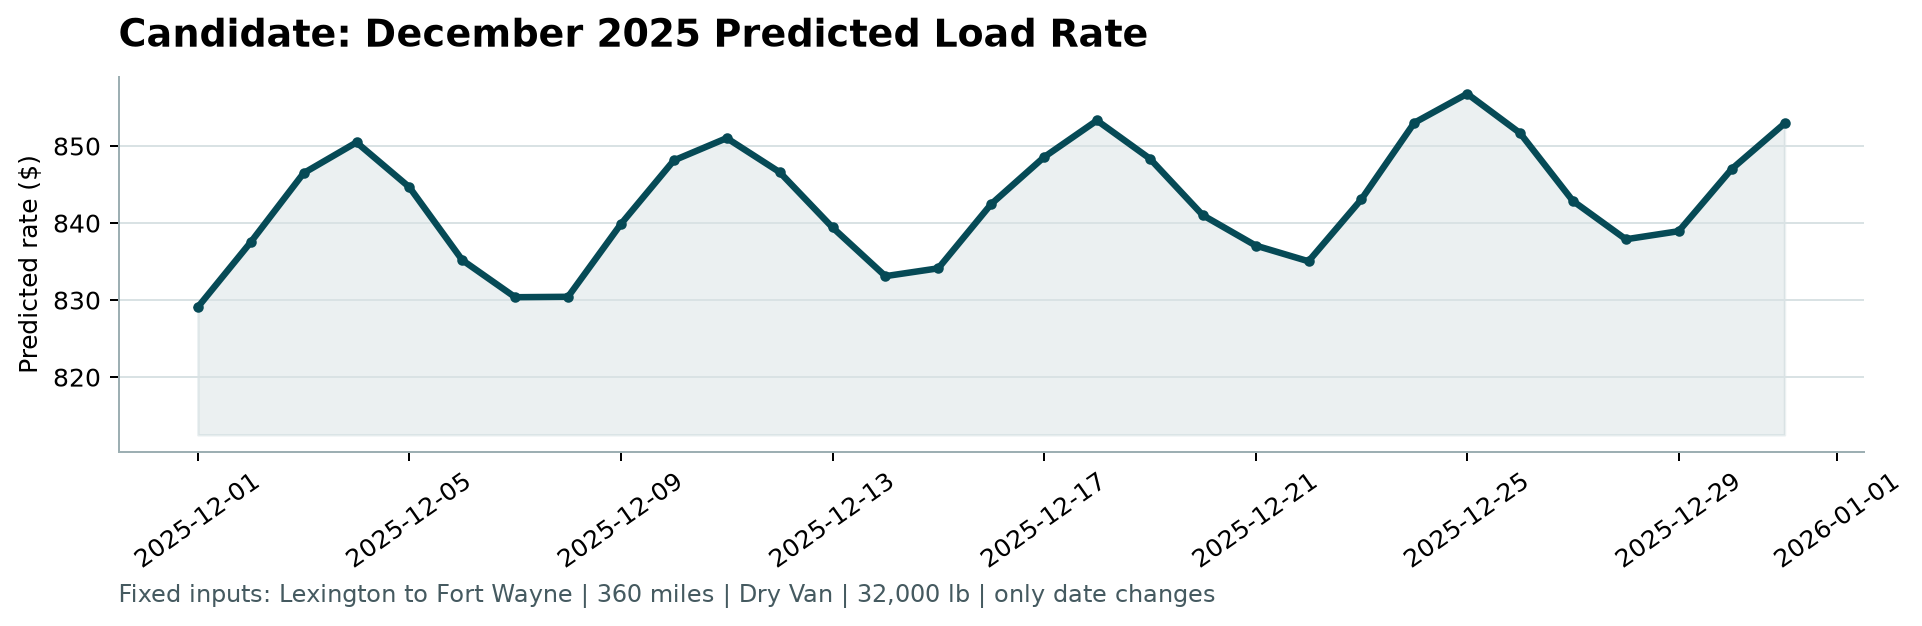

In [11]:
# Official scorer, unmodified
r = subprocess.run([sys.executable, score_script, "--predictions", pred_path, "--december-predictions", dec_path,
                    "--output-dir", os.path.join(OUT_DIR, "scorer_results")], capture_output=True, text=True)
print(r.stdout, r.stderr)
display(Image(os.path.join(OUT_DIR, "scorer_results", "candidate_december.png")))

The daily market level: what the model observed in the labeled months, and what the linear daily model gives, including Nov and Dec.

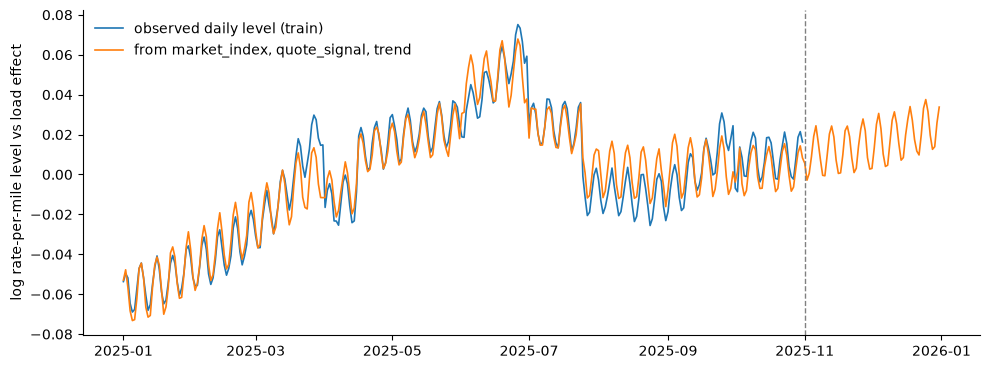

In [12]:
fit = model.daily_level(daily.index, daily)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(model.level.index, model.level.values, lw=1.2, label="observed daily level (train)")
ax.plot(fit.index, fit.values, lw=1.2, label="from market_index, quote_signal, trend")
ax.axvline(pd.Timestamp("2025-11-01"), color="grey", ls="--", lw=1)
ax.set_ylabel("log rate-per-mile level vs load effect")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "daily_level.png"), dpi=150)
plt.show()

## Notes and assumptions

- The main assumption is the upward time trend carrying into Nov and Dec. Forward tests favour including it, but if it does not continue, predictions would run about 4% high.
- The December market signals come from the feature columns of `validation.csv`. No labels are used anywhere for validation rows.
- Validation numbers come from holding out later months of `train-test.csv`. The real score is calculated by Spotter.
- The original assessment files are not changed. Cleaning (flipping negative weights) happens on copies in memory.